# 04. 불균형 처리 · 앙상블 · Ablation · 최종 모델

> README **7.3 불균형 데이터 처리**, **7.4 모델 성능 비교**, **7.7 Ablation**, **8. 최종 모델 및 결과 분석**에 대응하는 노트북입니다.

**03에서 넘어온 개선 목표**
1. Pastry Recall 개선 (Baseline 0.508)
2. Bumps ↔ Other_Faults 혼동 감소

**이 노트북의 흐름**

| 섹션 | 질문 |
|---|---|
| 7.3 | 어떤 불균형 처리가 약한 유형을 개선하는가? 무엇이 나빠지는가? |
| 7.4 | 불균형 처리 + 앙상블은 Baseline보다 얼마나 나은가? |
| 7.7 | 개선은 앙상블·BorderlineSMOTE·하이퍼파라미터 중 무엇 때문인가? 우연은 아닌가? |
| 7.5 보완 | 최종 후보는 처음 보는 공정 조건(Group CV)에서도 나은가? |
| 8 | 최종 모델 선정, 해석, Test 평가 |

**공통 조건:** 03과 동일 (`load_data()`, `config.CV`, `cv_utils.cv_run`). Sampling은 `imblearn` Pipeline으로 모델과 묶어 **각 Training fold 안에서만** 수행되며, Validation fold에는 원본 데이터만 사용됩니다.

In [1]:
import sys
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 노트북 위치와 무관하게 프로젝트 루트(src/config.py가 있는 폴더)를 찾는다
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# 한글 폰트: OS별로 있는 폰트를 순서대로 사용
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic",
                               "Noto Sans CJK KR", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 200)

In [2]:
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier, VotingClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import classification_report, f1_score
from sklearn.base import clone
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from xgboost import XGBClassifier

from config import CV, RANDOM_STATE as R
from load_data import load_data
from evaluate import log_result
from cv_utils import cv_run, summarize, per_class_f1
from plotting import plot_confusion_matrix

X_train, X_test, y_train, y_test = load_data()
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

le = LabelEncoder()
y_enc = le.fit_transform(y_train)
CLASSES = le.classes_
C = {name: i for i, name in enumerate(CLASSES)}      # SMOTE 목표 건수 지정용
decode = lambda p: le.inverse_transform(p)

results = {}   # 실험명 → cv_run 결과

def run(name, model, note=""):
    res = cv_run(model, X_train, y_enc, CV)
    results[name] = res
    log_result(name, y_train, decode(res["pred"]), note=note)
    return res

def table(names, classes=None):
    df = pd.DataFrame([summarize(n, results[n], y_enc) for n in names]).set_index("실험")
    df = df[["MacroF1_CV예측", "MacroF1_fold평균", "MacroF1_std", "Accuracy"]]
    pc = pd.DataFrame({n: per_class_f1(results[n], y_enc, CLASSES) for n in names}).T
    return pd.concat([df, pc[classes] if classes else pc], axis=1)

print("Train fold 하나의 유형별 학습 건수(근사):")
print((pd.Series(y_train).value_counts() * 0.8).astype(int).to_string())

Train fold 하나의 유형별 학습 건수(근사):
target
Other_Faults    430
Bumps           256
K_Scratch       250
Z_Scratch       121
Pastry          100
Stains           46
Dirtiness        35


## 7.3 불균형 처리 실험 (GradientBoosting 기준)

GradientBoosting으로 처리 방법을 비교합니다. 하이퍼파라미터가 고정된 하나의 모델에서 **처리 방법만 바꿔야** 효과를 비교할 수 있기 때문입니다.

| 실험 | 확인하려는 것 |
|---|---|
| 희귀 2종(Stains, Dirtiness)만 SMOTE → 80/120/180건 | 건수가 가장 적은 유형을 늘리면 Macro F1이 오르는가? |
| 전체 SMOTE | 모든 유형을 최다 유형 수준으로 맞추면? |
| Pastry만 SMOTE → 200/250건 | 가장 약한 유형 하나만 보강하면? |
| 저성능 3종 (Pastry 200, Bumps 320, Dirtiness 120) | Baseline에서 약했던 유형을 함께 보강하면? |
| BorderlineSMOTE | 오분류가 유형 **경계**에 집중되어 있으므로, 경계 부근 샘플 중심으로 합성하면? |

SMOTE는 Train fold 하나의 Dirtiness가 약 35건뿐이어서 `k_neighbors=3`으로 설정했습니다.

In [3]:
gb = lambda: GradientBoostingClassifier(random_state=R)
smote = lambda strategy="auto": SMOTE(sampling_strategy=strategy, k_neighbors=3, random_state=R)
bsmote = lambda: BorderlineSMOTE(k_neighbors=3, m_neighbors=5, random_state=R)

experiments = {
    "GB_처리없음": gb(),
    "GB_희귀2종_80": make_pipeline(smote({C["Stains"]: 80, C["Dirtiness"]: 80}), gb()),
    "GB_희귀2종_120": make_pipeline(smote({C["Stains"]: 120, C["Dirtiness"]: 120}), gb()),
    "GB_희귀2종_180": make_pipeline(smote({C["Stains"]: 180, C["Dirtiness"]: 180}), gb()),
    "GB_전체SMOTE": make_pipeline(smote(), gb()),
    "GB_Pastry_200": make_pipeline(smote({C["Pastry"]: 200}), gb()),
    "GB_Pastry_250": make_pipeline(smote({C["Pastry"]: 250}), gb()),
    "GB_저성능3종": make_pipeline(smote({C["Pastry"]: 200, C["Bumps"]: 320, C["Dirtiness"]: 120}), gb()),
    "GB_BorderlineSMOTE": make_pipeline(bsmote(), gb()),
}
for name, model in experiments.items():
    run(name, model, note="7.3 불균형 처리 비교 (GB)")

imb_table = table(list(experiments), ["Pastry", "Bumps", "Other_Faults", "K_Scratch",
                                      "Z_Scratch", "Stains", "Dirtiness"])
imb_table.round(3)

    실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_처리없음        0.7974       0.7789 0.7790 7.3 불균형 처리 비교 (GB)


       실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_희귀2종_80        0.8025       0.7780 0.7784 7.3 불균형 처리 비교 (GB)


        실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_희귀2종_120        0.8019       0.7742 0.7738 7.3 불균형 처리 비교 (GB)


        실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_희귀2종_180        0.8017       0.7787 0.7790 7.3 불균형 처리 비교 (GB)


       실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_전체SMOTE        0.8094       0.7829 0.7822 7.3 불균형 처리 비교 (GB)


          실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_Pastry_200        0.8078       0.7831 0.7816 7.3 불균형 처리 비교 (GB)


          실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_Pastry_250        0.8039       0.7798 0.7784 7.3 불균형 처리 비교 (GB)


     실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_저성능3종        0.8138       0.7912 0.7899 7.3 불균형 처리 비교 (GB)


               실험명 담당자  Macro_F1  Weighted_F1    정확도                 비고
GB_BorderlineSMOTE        0.8181       0.7911 0.7899 7.3 불균형 처리 비교 (GB)


,MacroF1_CV예측,MacroF1_fold평균,MacroF1_std,Accuracy,Pastry,Bumps,Other_Faults,K_Scratch,Z_Scratch,Stains,Dirtiness
GB_처리없음,0.7970,0.7950,0.0170,0.7790,0.5630,0.6580,0.7330,0.9610,0.9360,0.9200,0.8100
GB_희귀2종_80,0.8020,0.8010,0.0140,0.7780,0.5630,0.6540,0.7300,0.9600,0.9400,0.9140,0.8570
GB_희귀2종_120,0.8020,0.7980,0.0190,0.7740,0.5680,0.6500,0.7200,0.9580,0.9430,0.8970,0.8780
GB_희귀2종_180,0.8020,0.8010,0.0210,0.7790,0.5650,0.6600,0.7270,0.9580,0.9460,0.9310,0.8240
GB_전체SMOTE,0.8090,0.8080,0.0120,0.7820,0.6350,0.6820,0.7240,0.9520,0.9070,0.9400,0.8260
GB_Pastry_200,0.8080,0.8060,0.0120,0.7820,0.6390,0.6600,0.7290,0.9550,0.9390,0.9290,0.8050
GB_Pastry_250,0.8040,0.8020,0.0070,0.7780,0.6570,0.6540,0.7190,0.9600,0.9350,0.9300,0.7730
GB_저성능3종,0.8140,0.8120,0.0220,0.7900,0.5840,0.6790,0.7430,0.9630,0.9470,0.9200,0.8600
GB_BorderlineSMOTE,0.8180,0.8180,0.0090,0.7900,0.6590,0.6900,0.7250,0.9680,0.9150,0.9400,0.8290


In [4]:
# 처리 없음 대비 변화량
(imb_table.drop(columns=["MacroF1_fold평균", "MacroF1_std", "Accuracy"])
 - imb_table.loc["GB_처리없음"]).drop(index="GB_처리없음").round(3)

,Accuracy,Bumps,Dirtiness,K_Scratch,MacroF1_CV예측,MacroF1_fold평균,MacroF1_std,Other_Faults,Pastry,Stains,Z_Scratch
GB_희귀2종_80,NaN,-0.0040,0.0480,-0.0020,0.0050,NaN,NaN,-0.0030,0.0000,-0.0070,0.0040
GB_희귀2종_120,NaN,-0.0080,0.0690,-0.0030,0.0050,NaN,NaN,-0.0130,0.0050,-0.0240,0.0070
GB_희귀2종_180,NaN,0.0020,0.0140,-0.0030,0.0040,NaN,NaN,-0.0060,0.0020,0.0110,0.0100
GB_전체SMOTE,NaN,0.0240,0.0170,-0.0100,0.0120,NaN,NaN,-0.0090,0.0720,0.0200,-0.0290
GB_Pastry_200,NaN,0.0020,-0.0050,-0.0070,0.0100,NaN,NaN,-0.0040,0.0760,0.0080,0.0030
GB_Pastry_250,NaN,-0.0040,-0.0370,-0.0020,0.0070,NaN,NaN,-0.0140,0.0940,0.0090,-0.0010
GB_저성능3종,NaN,0.0210,0.0510,0.0020,0.0160,NaN,NaN,0.0100,0.0210,0.0000,0.0110
GB_BorderlineSMOTE,NaN,0.0320,0.0200,0.0060,0.0210,NaN,NaN,-0.0080,0.0960,0.0200,-0.0210


**확인 결과** (처리 없음 대비, CV 예측 기준)

| 방식 | Macro F1 변화 | 핵심 변화 |
|---|---:|---|
| 희귀 2종만 (80/120/180건) | +0.004 ~ +0.005 | Dirtiness F1은 올랐지만(최대 +0.069) 다른 유형은 소폭 하락 |
| 전체 SMOTE | +0.012 | Pastry +0.072, Bumps +0.024 / **Z_Scratch −0.029** |
| Pastry만 (200/250건) | +0.010 / +0.007 | Pastry +0.076 / +0.094, 250건에서는 Dirtiness −0.037 |
| 저성능 3종 | +0.016 | 대부분 유형이 소폭 개선 |
| **BorderlineSMOTE** | **+0.021** | Pastry **+0.096**, Bumps +0.032 / Z_Scratch −0.021 |

**해석**
- **"적은 유형"보다 "약한 유형·경계"를 보강하는 쪽이 효과적이었습니다.** Stains·Dirtiness는 Baseline부터 F1이 0.8 이상이라 이들만 늘렸을 때의 Macro F1 개선은 +0.005 수준이었습니다.
- BorderlineSMOTE가 가장 크게 개선되었고 fold 간 표준편차도 0.009로 가장 작았습니다. 오분류가 유형 **경계**에 집중되어 있다는 03의 관찰과 맞는 결과입니다.
- **Trade-off:** 효과가 컸던 방법일수록 Z_Scratch·Other_Faults가 소폭 하락했습니다. 합성 샘플이 기존에 잘 분리되던 경계를 일부 흐렸을 가능성이 있습니다(가설).
- **주의:** 방법 간 차이(0.005 ~ 0.02)는 fold 간 변동(0.007 ~ 0.022)과 비슷한 크기입니다. BorderlineSMOTE의 우위는 이 단일 CV에서 가장 뚜렷하지만, 반복 실험 없이 확정하지는 않습니다.

**결정:** 이후 실험의 불균형 처리 방법으로 **BorderlineSMOTE**를 사용합니다.

## 7.4 앙상블 및 Baseline 대비 비교

GradientBoosting과 XGBoost에 각각 BorderlineSMOTE를 적용한 뒤 **Soft Voting**(두 모델의 예측 확률 평균)으로 결합합니다. 두 Boosting 모델은 학습 방식이 달라 오류 패턴이 일부 다를 수 있고, 확률을 평균하면 한 모델의 불안정한 예측이 완화될 수 있다는 가정입니다.

In [5]:
XGB_TUNED = dict(n_estimators=500, learning_rate=0.1, max_depth=6)

def xgb_default():
    return XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                         random_state=R, n_jobs=1)

def xgb_tuned():
    return XGBClassifier(**XGB_TUNED, objective="multi:softprob",
                         eval_metric="mlogloss", random_state=R, n_jobs=1)

def make_ensemble(sampling=True):
    wrap = (lambda m: make_pipeline(bsmote(), m)) if sampling else (lambda m: m)
    return VotingClassifier([("gb", wrap(gb())), ("xgb", wrap(xgb_tuned()))], voting="soft")

run("XGB_기본값_처리없음", xgb_default(), note="Baseline (03과 동일)")
run("Ensemble_BorderlineSMOTE", make_ensemble(True), note="GB+XGB(tuned) 각각 BorderlineSMOTE, Soft Voting")

main_table = table(["XGB_기본값_처리없음", "GB_처리없음", "GB_BorderlineSMOTE", "Ensemble_BorderlineSMOTE"])
main_table.round(3)

         실험명 담당자  Macro_F1  Weighted_F1    정확도                비고
XGB_기본값_처리없음        0.8143       0.7936 0.7945 Baseline (03과 동일)


                     실험명 담당자  Macro_F1  Weighted_F1    정확도                                            비고
Ensemble_BorderlineSMOTE        0.8245       0.8008 0.8009 GB+XGB(tuned) 각각 BorderlineSMOTE, Soft Voting


,MacroF1_CV예측,MacroF1_fold평균,MacroF1_std,Accuracy,Bumps,Dirtiness,K_Scratch,Other_Faults,Pastry,Stains,Z_Scratch
XGB_기본값_처리없음,0.8140,0.8110,0.0310,0.7940,0.6760,0.8540,0.9680,0.7520,0.5610,0.9390,0.9500
GB_처리없음,0.7970,0.7950,0.0170,0.7790,0.6580,0.8100,0.9610,0.7330,0.5630,0.9200,0.9360
GB_BorderlineSMOTE,0.8180,0.8180,0.0090,0.7900,0.6900,0.8290,0.9680,0.7250,0.6590,0.9400,0.9150
Ensemble_BorderlineSMOTE,0.8240,0.8240,0.0100,0.8010,0.7030,0.8370,0.9650,0.7460,0.6460,0.9490,0.9250


**확인 결과**
- 앙상블 + BorderlineSMOTE는 Macro F1 **0.824**(CV 예측 기준, fold 평균도 0.824 ± 0.010)로, XGBoost Baseline(0.814)보다 0.010 높습니다.
- 유형별로는 Pastry(0.561 → 0.646), Bumps(0.676 → 0.703)가 개선되고, Z_Scratch(0.950 → 0.925), Dirtiness(0.854 → 0.837)가 하락했습니다.
- 다만 GB + BorderlineSMOTE 단독(0.818)과의 차이는 0.006에 불과합니다.

**질문:** 이 개선은 무엇 때문인가? → 7.7 Ablation

## 7.7 Ablation: 개선은 어디서 왔는가?

최종 후보(앙상블)는 Baseline XGBoost와 비교해 **세 가지가 동시에** 다릅니다.
1. XGBoost 하이퍼파라미터 (기본값 `n_estimators=100, learning_rate=0.3` → `500, 0.1`)
2. BorderlineSMOTE 적용
3. GradientBoosting과의 Soft Voting

이대로는 "앙상블 덕분에 좋아졌다"고 말할 수 없으므로, 요소를 하나씩 바꿔 기여도를 분리합니다.

| 실험 | XGB 파라미터 | BorderlineSMOTE | GB 결합 |
|---|---|---|---|
| A. XGB 기본값 (Baseline) | 기본값 | – | – |
| B. XGB 튜닝값 | 500 / 0.1 | – | – |
| C. XGB 튜닝값 + BSMOTE | 500 / 0.1 | ✓ | – |
| D. GB (Baseline) | – | – | GB 단독 |
| E. GB + BSMOTE | – | ✓ | GB 단독 |
| F. 앙상블 (Sampling 없음) | 500 / 0.1 | – | ✓ |
| G. 앙상블 + BSMOTE (최종 후보) | 500 / 0.1 | ✓ | ✓ |

In [6]:
run("XGB_튜닝값_처리없음", xgb_tuned(), note="Ablation B")
run("XGB_튜닝값_BorderlineSMOTE", make_pipeline(bsmote(), xgb_tuned()), note="Ablation C")
run("Ensemble_처리없음", make_ensemble(False), note="Ablation F")

ABL = {"A": "XGB_기본값_처리없음", "B": "XGB_튜닝값_처리없음", "C": "XGB_튜닝값_BorderlineSMOTE",
       "D": "GB_처리없음", "E": "GB_BorderlineSMOTE", "F": "Ensemble_처리없음",
       "G": "Ensemble_BorderlineSMOTE"}
abl_table = table(list(ABL.values()), ["Pastry", "Bumps", "Other_Faults", "Z_Scratch", "Dirtiness"])
abl_table.index = [f"{k}. {v}" for k, v in ABL.items()]
abl_table.round(3)

         실험명 담당자  Macro_F1  Weighted_F1    정확도         비고
XGB_튜닝값_처리없음        0.8100       0.7900 0.7906 Ablation B


                    실험명 담당자  Macro_F1  Weighted_F1    정확도         비고
XGB_튜닝값_BorderlineSMOTE        0.8160       0.7987 0.7990 Ablation C


          실험명 담당자  Macro_F1  Weighted_F1    정확도         비고
Ensemble_처리없음        0.8177       0.7975 0.7983 Ablation F


,MacroF1_CV예측,MacroF1_fold평균,MacroF1_std,Accuracy,Pastry,Bumps,Other_Faults,Z_Scratch,Dirtiness
A. XGB_기본값_처리없음,0.8140,0.8110,0.0310,0.7940,0.5610,0.6760,0.7520,0.9500,0.8540
B. XGB_튜닝값_처리없음,0.8100,0.8070,0.0280,0.7910,0.5940,0.6710,0.7440,0.9400,0.8240
C. XGB_튜닝값_BorderlineSMOTE,0.8160,0.8150,0.0150,0.7990,0.6220,0.7000,0.7500,0.9290,0.7900
D. GB_처리없음,0.7970,0.7950,0.0170,0.7790,0.5630,0.6580,0.7330,0.9360,0.8100
E. GB_BorderlineSMOTE,0.8180,0.8180,0.0090,0.7900,0.6590,0.6900,0.7250,0.9150,0.8290
F. Ensemble_처리없음,0.8180,0.8150,0.0260,0.7980,0.5960,0.6770,0.7530,0.9530,0.8330
G. Ensemble_BorderlineSMOTE,0.8240,0.8240,0.0100,0.8010,0.6460,0.7030,0.7460,0.9250,0.8370


In [7]:
f = {k: f1_score(y_enc, results[v]["pred"], average="macro") for k, v in ABL.items()}
pd.DataFrame([
    ("XGB 하이퍼파라미터 변경", "B − A", f["B"] - f["A"]),
    ("XGB에 BorderlineSMOTE", "C − B", f["C"] - f["B"]),
    ("GB에 BorderlineSMOTE", "E − D", f["E"] - f["D"]),
    ("앙상블 효과 (Sampling 없음)", "F − B", f["F"] - f["B"]),
    ("앙상블 효과 (BSMOTE 적용 후)", "G − C", f["G"] - f["C"]),
    ("앙상블에 BorderlineSMOTE", "G − F", f["G"] - f["F"]),
    ("전체 개선", "G − A", f["G"] - f["A"]),
], columns=["요소", "비교", "Macro F1 변화 (CV 예측 기준)"]).set_index("요소").round(4)

,비교,Macro F1 변화 (CV 예측 기준)
요소,,
XGB 하이퍼파라미터 변경,B − A,-0.0043
XGB에 BorderlineSMOTE,C − B,0.0060
GB에 BorderlineSMOTE,E − D,0.0207
앙상블 효과 (Sampling 없음),F − B,0.0077
앙상블 효과 (BSMOTE 적용 후),G − C,0.0085
앙상블에 BorderlineSMOTE,G − F,0.0068
전체 개선,G − A,0.0101


### 차이가 우연이 아닌지: 반복 CV (seed 0, 1, 2)

위 비교는 CV seed 하나(42)의 결과입니다. Ablation 차이(0.01 안팎)가 fold 간 변동(표준편차 0.015~0.03)보다 작을 수 있으므로, **CV seed 3개 × 5 fold = 15번** 같은 분할에서 짝지어 비교합니다.

In [8]:
REPEAT = {"A": xgb_default, "B": xgb_tuned,
          "C": lambda: make_pipeline(bsmote(), xgb_tuned()),
          "G": lambda: make_ensemble(True)}

fold_scores = {k: [] for k in REPEAT}
for s in [0, 1, 2]:
    sp = StratifiedKFold(5, shuffle=True, random_state=s)
    for k, make in REPEAT.items():
        fold_scores[k].extend(cv_run(make(), X_train, y_enc, sp)["folds"]["f1_macro"])
fold_scores = {k: np.array(v) for k, v in fold_scores.items()}

rep = pd.DataFrame({k: {"Macro F1 평균 (15 fold)": v.mean(), "표준편차": v.std()}
                    for k, v in fold_scores.items()}).T
display(rep.round(4))

rows = []
for label, a, b in [("하이퍼파라미터 (B−A)", "B", "A"), ("BSMOTE on XGB (C−B)", "C", "B"),
                    ("GB 결합 (G−C)", "G", "C"), ("전체 (G−A)", "G", "A")]:
    d = fold_scores[a] - fold_scores[b]
    rows.append({"비교": label, "평균 차이": d.mean(), "우세 fold": f"{int((d > 0).sum())}/15"})
pd.DataFrame(rows).set_index("비교").round(4)

,Macro F1 평균 (15 fold),표준편차
A,0.8146,0.0201
B,0.8100,0.0251
C,0.8163,0.0207
G,0.8160,0.0229


,평균 차이,우세 fold
비교,,
하이퍼파라미터 (B−A),-0.0046,6/15
BSMOTE on XGB (C−B),0.0063,7/15
GB 결합 (G−C),-0.0003,6/15
전체 (G−A),0.0014,8/15


**확인 결과 (단일 CV, seed 42)**
- XGBoost 하이퍼파라미터 변경(B − A)은 **오히려 −0.004**였습니다. 개선 요인이 아닙니다.
- BorderlineSMOTE는 XGB에서 +0.006, GB에서 +0.021, 앙상블에서 +0.007로 모든 모델에서 플러스였습니다.
- GB 결합(앙상블)은 Sampling 유무와 관계없이 +0.008 안팎이었습니다.

**확인 결과 (반복 CV, seed 0·1·2 × 5 fold = 15회)**

| 비교 | 평균 차이 | 우세 fold |
|---|---:|---:|
| 하이퍼파라미터 (B − A) | −0.005 | 6/15 |
| BSMOTE on XGB (C − B) | +0.006 | 7/15 |
| GB 결합 (G − C) | **−0.000** | 6/15 |
| 전체 (G − A) | **+0.001** | 8/15 |

- 15회 평균으로 보면 A 0.815, C 0.816, G 0.816으로 **세 모델이 사실상 같습니다.** seed 42에서 보인 +0.010 개선은 다른 분할에서 재현되지 않았습니다.
- fold 간 표준편차(0.020 ~ 0.025)가 모델 간 차이보다 10배 이상 큽니다.

**해석**
- **Stratified CV의 Macro F1 기준으로는 앙상블 + BorderlineSMOTE가 Baseline보다 낫다고 말할 근거가 약합니다.** seed 42 하나의 CV 결과로 모델을 고르면 분할 운에 따른 차이를 개선으로 오해할 수 있습니다.
- 가장 일관된 신호는 BorderlineSMOTE의 **유형별 변화**(Pastry·Bumps 개선)이며, Macro F1 합계에서는 다른 유형의 하락과 상쇄됩니다.
- 하이퍼파라미터 변경은 근거 없이 바뀌었던 부분이므로, 최종 후보를 정할 때 다시 검토가 필요합니다.

## 7.5 보완: 최종 후보의 Group CV 성능

03에서 공정 조건 조합이 같은 결함이 Train/Validation에 함께 들어가면 성능이 과대평가될 수 있음을 확인했습니다. 최종 후보도 Group CV로 평가해, **처음 보는 공정 조건**에서 Baseline보다 나은지 확인합니다.

In [9]:
KEY = ["TypeOfSteel_A300", "Steel_Plate_Thickness", "Length_of_Conveyer"]
groups = X_train[KEY].astype(str).agg("_".join, axis=1)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=R)

group_res = {
    "A. XGB 기본값": cv_run(xgb_default(), X_train, y_enc, sgkf, groups),
    "C. XGB 튜닝값 + BSMOTE": cv_run(make_pipeline(bsmote(), xgb_tuned()), X_train, y_enc, sgkf, groups),
    "G. 앙상블 + BSMOTE": cv_run(make_ensemble(True), X_train, y_enc, sgkf, groups),
}
strat_map = {"A. XGB 기본값": "A", "C. XGB 튜닝값 + BSMOTE": "C", "G. 앙상블 + BSMOTE": "G"}

gtab = pd.DataFrame({
    n: {"Stratified (CV 예측)": f[strat_map[n]],
        "Group (CV 예측)": f1_score(y_enc, r["pred"], average="macro"),
        "Group (fold 평균)": r["folds"]["f1_macro"].mean(),
        "Group (fold std)": r["folds"]["f1_macro"].std(ddof=0)}
    for n, r in group_res.items()}).T
gtab["하락폭"] = gtab["Group (CV 예측)"] - gtab["Stratified (CV 예측)"]
display(gtab.round(3))

pd.DataFrame({n: per_class_f1(r, y_enc, CLASSES) for n, r in group_res.items()}).round(3)

,Stratified (CV 예측),Group (CV 예측),Group (fold 평균),Group (fold std),하락폭
A. XGB 기본값,0.8140,0.7540,0.7200,0.0440,-0.0600
C. XGB 튜닝값 + BSMOTE,0.8160,0.7650,0.7390,0.0180,-0.0510
G. 앙상블 + BSMOTE,0.8240,0.7670,0.7420,0.0280,-0.0580


,A. XGB 기본값,C. XGB 튜닝값 + BSMOTE,G. 앙상블 + BSMOTE
Bumps,0.6350,0.6470,0.6690
Dirtiness,0.7380,0.7760,0.7440
K_Scratch,0.9030,0.9030,0.9070
Other_Faults,0.6700,0.6480,0.6510
Pastry,0.5430,0.5800,0.5940
Stains,0.9470,0.9400,0.9320
Z_Scratch,0.8440,0.8600,0.8700


**확인 결과 (Group CV, fold 평균)**
- A. XGB 기본값 0.720 ± 0.044 / C. XGB 튜닝값 + BSMOTE 0.739 ± 0.018 / G. 앙상블 + BSMOTE **0.742 ± 0.028**
- 처음 보는 공정 조건에서는 BorderlineSMOTE를 적용한 두 후보가 Baseline보다 약 **+0.02** 높고, fold 간 변동도 작았습니다(특히 C).
- 유형별로 G는 Baseline 대비 Bumps(0.635 → 0.669), Pastry(0.543 → 0.594), Z_Scratch(0.844 → 0.870)가 개선되고, Other_Faults(0.670 → 0.651)는 하락했습니다.
- 세 모델 모두 Stratified 대비 5 ~ 6%p 하락하므로, 새 공정 조건에 대한 과대평가 문제는 모델 선택으로 해결되지 않습니다.

**해석:** Stratified 반복 CV에서는 차이가 사라졌지만, Group CV에서는 BorderlineSMOTE 적용 모델이 일관되게 높았습니다. 공정 조건 지름길을 쓸 수 없을 때 경계 부근 보강이 더 도움이 되었을 가능성이 있습니다(가설, Group CV도 seed 하나의 결과).

# 8. 최종 모델 선정 및 해석

## 8.1 최종 모델

**최종 모델 (팀 공유용 가정):** GradientBoosting + XGBoost Soft Voting, 각 모델에 BorderlineSMOTE 적용

| 구성 요소 | 설정 |
|---|---|
| BorderlineSMOTE | `k_neighbors=3`, `m_neighbors=5`, `sampling_strategy="auto"`, `random_state=42` |
| GradientBoosting | 기본값, `random_state=42` |
| XGBoost | `n_estimators=500`, `learning_rate=0.1`, `max_depth=6`, `random_state=42` |
| 입력 Feature | 전처리된 원본 26개 |

**선정 근거**
1. 공식 기준(Stratified 5-fold, seed 42)에서 Macro F1 **0.824**로 가장 높고, fold 간 표준편차(0.010)도 작습니다.
2. 개선 목표였던 **Pastry Recall 0.508 → 0.651**, Bumps → Other_Faults 오분류 87 → 65건으로 줄었습니다.
3. Group CV에서도 0.742로 후보 중 가장 높았습니다.

**⚠️ 팀 논의 필요: 선정 근거의 한계**
- 반복 CV(15회)에서는 Baseline XGBoost와의 Macro F1 차이가 +0.001로 사라졌고, XGB 튜닝값 + BSMOTE(C)와도 같았습니다.
- Group CV에서 C(0.739)와 G(0.742)의 차이도 fold 간 변동보다 작습니다.
- 성능이 같다면 **더 단순한 C(XGB 단독 + BorderlineSMOTE)**가 학습 시간·해석·대시보드 설명 면에서 유리합니다.

→ 최종 모델을 G로 유지할지, C로 바꿀지는 Test 평가 전에 팀에서 결정해야 합니다. 이 노트북은 공유용으로 G를 가정합니다.

In [10]:
FINAL_NAME = "Ensemble_BorderlineSMOTE"
final_res = results[FINAL_NAME]
base_res = results["XGB_기본값_처리없음"]
pred_final = decode(final_res["pred"])

print(f"[최종 모델: {FINAL_NAME}] Train 5-fold CV 예측 기준\n")
print(classification_report(y_train, pred_final, digits=3))

[최종 모델: Ensemble_BorderlineSMOTE] Train 5-fold CV 예측 기준

              precision    recall  f1-score   support

       Bumps      0.674     0.735     0.703       321
   Dirtiness      0.857     0.818     0.837        44
   K_Scratch      0.959     0.971     0.965       313
Other_Faults      0.774     0.719     0.746       538
      Pastry      0.641     0.651     0.646       126
      Stains      0.933     0.966     0.949        58
   Z_Scratch      0.916     0.934     0.925       152

    accuracy                          0.801      1552
   macro avg      0.822     0.828     0.824      1552
weighted avg      0.802     0.801     0.801      1552



In [11]:
from sklearn.metrics import precision_recall_fscore_support as prfs

def class_metrics(res):
    p, r, f, _ = prfs(y_enc, res["pred"], labels=range(len(CLASSES)))
    return pd.DataFrame({"Precision": p, "Recall": r, "F1": f}, index=CLASSES)

b, fm = class_metrics(base_res), class_metrics(final_res)
change = pd.concat({"Baseline": b, "최종": fm, "변화": fm - b}, axis=1)
change.sort_values(("변화", "F1"), ascending=False).round(3)

Baseline                      최종                      변화                
             Precision Recall     F1 Precision Recall     F1 Precision  Recall      F1
Pastry          0.6270 0.5080 0.5610    0.6410 0.6510 0.6460    0.0130  0.1430  0.0840
Bumps           0.6700 0.6820 0.6760    0.6740 0.7350 0.7030    0.0050  0.0530  0.0280
Stains          0.9470 0.9310 0.9390    0.9330 0.9660 0.9490   -0.0140  0.0340  0.0100
K_Scratch       0.9710 0.9650 0.9680    0.9590 0.9710 0.9650   -0.0120  0.0060 -0.0030
Other_Faults    0.7330 0.7710 0.7520    0.7740 0.7190 0.7460    0.0410 -0.0520 -0.0060
Dirtiness       0.9210 0.7950 0.8540    0.8570 0.8180 0.8370   -0.0640  0.0230 -0.0160
Z_Scratch       0.9540 0.9470 0.9500    0.9160 0.9340 0.9250   -0.0380 -0.0130 -0.0250

저장: /home/claude/project/figures/cv_confusion_matrix_final.png


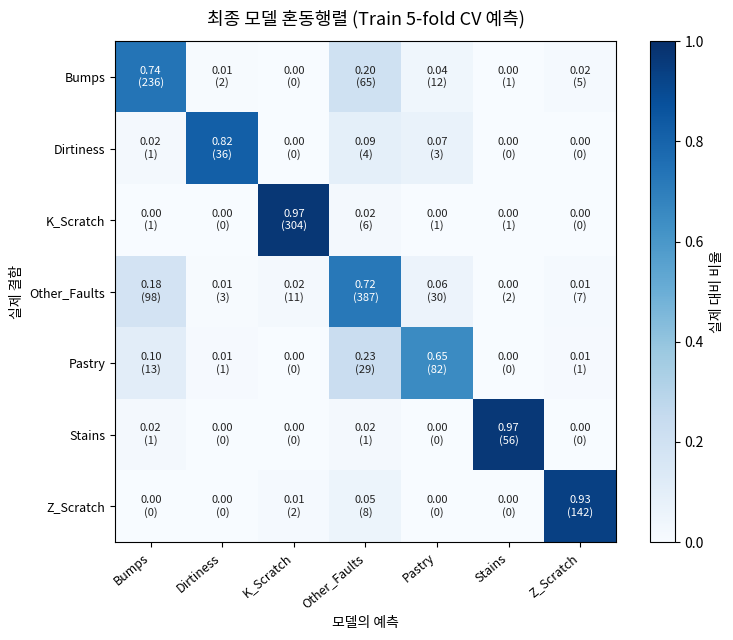

,Baseline,최종,변화
실제 → 예측,,,
Bumps → Other_Faults,87,65,-22
Other_Faults → Bumps,85,98,13
Pastry → Other_Faults,42,29,-13
Other_Faults → Pastry,24,30,6


In [12]:
fig, ax, cm_final = plot_confusion_matrix(
    y_train, pred_final, labels=list(CLASSES), normalize=True,
    title="최종 모델 혼동행렬 (Train 5-fold CV 예측)",
    save_name="cv_confusion_matrix_final.png")
plt.show()

from sklearn.metrics import confusion_matrix
cm_base = pd.DataFrame(confusion_matrix(y_enc, base_res["pred"]), index=CLASSES, columns=CLASSES)
cm_fin = pd.DataFrame(cm_final, index=CLASSES, columns=CLASSES)
pairs = [("Bumps", "Other_Faults"), ("Other_Faults", "Bumps"),
         ("Pastry", "Other_Faults"), ("Other_Faults", "Pastry")]
pd.DataFrame([{"실제 → 예측": f"{a} → {p}", "Baseline": cm_base.loc[a, p],
               "최종": cm_fin.loc[a, p], "변화": cm_fin.loc[a, p] - cm_base.loc[a, p]}
              for a, p in pairs]).set_index("실제 → 예측")

## 모델 비교 시각화

왼쪽 그래프의 세로축은 0.75부터 시작하므로, 막대 높이 차이가 실제 차이보다 크게 보입니다. 반복 CV 결과(7.7)와 함께 해석하세요.

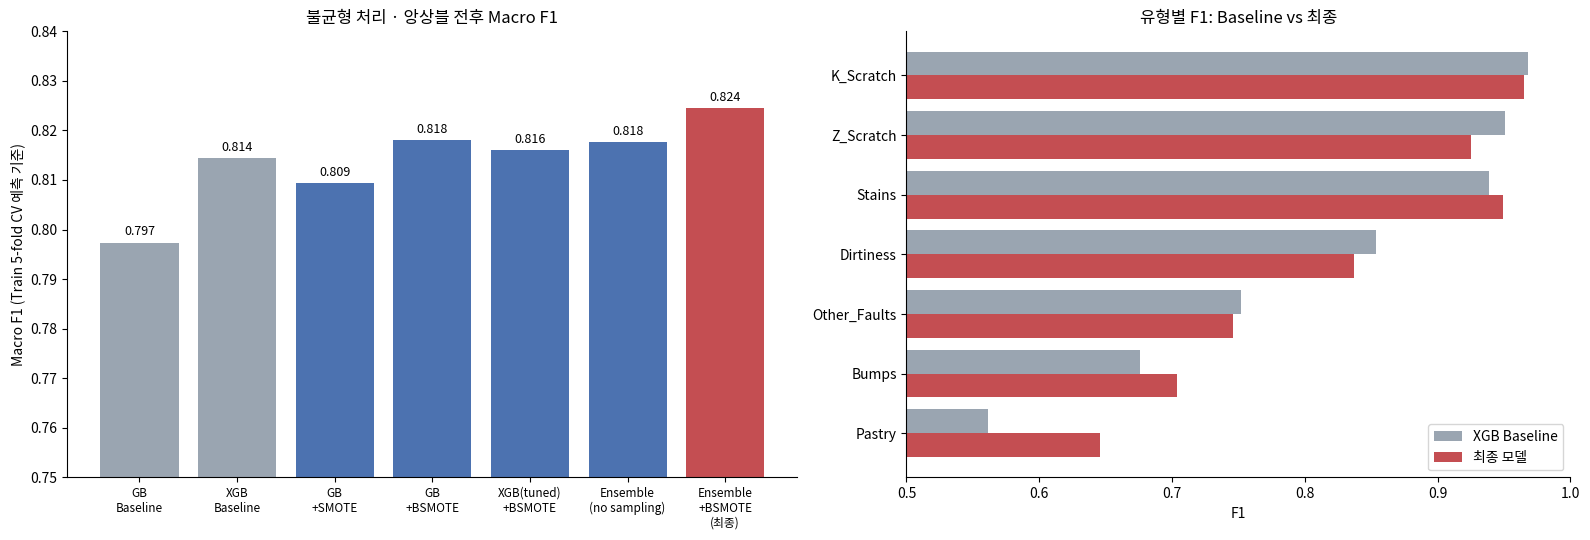

In [13]:
compare = ["GB_처리없음", "XGB_기본값_처리없음", "GB_전체SMOTE", "GB_BorderlineSMOTE",
           "XGB_튜닝값_BorderlineSMOTE", "Ensemble_처리없음", "Ensemble_BorderlineSMOTE"]
labels = ["GB\nBaseline", "XGB\nBaseline", "GB\n+SMOTE", "GB\n+BSMOTE",
          "XGB(tuned)\n+BSMOTE", "Ensemble\n(no sampling)", "Ensemble\n+BSMOTE\n(최종)"]
scores = [f1_score(y_enc, results[n]["pred"], average="macro") for n in compare]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
colors = ["#9AA5B1"] * 2 + ["#4C72B0"] * 4 + ["#C44E52"]
b_ = axes[0].bar(labels, scores, color=colors)
axes[0].bar_label(b_, fmt="%.3f", padding=3, fontsize=9)
axes[0].set_ylim(0.75, 0.84)
axes[0].set_ylabel("Macro F1 (Train 5-fold CV 예측 기준)")
axes[0].set_title("불균형 처리 · 앙상블 전후 Macro F1")
axes[0].tick_params(axis="x", labelsize=8.5)

order = b["F1"].sort_values().index
pos = np.arange(len(order))
axes[1].barh(pos + 0.2, b.loc[order, "F1"], height=0.4, color="#9AA5B1", label="XGB Baseline")
axes[1].barh(pos - 0.2, fm.loc[order, "F1"], height=0.4, color="#C44E52", label="최종 모델")
axes[1].set_yticks(pos, order)
axes[1].set_xlim(0.5, 1.0)
axes[1].set_xlabel("F1")
axes[1].set_title("유형별 F1: Baseline vs 최종")
axes[1].legend(loc="lower right")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 8.3 최종 모델 해석: Permutation Importance

03에서는 XGBoost Baseline 기준으로 중요도를 봤습니다. 최종 모델(앙상블 + BSMOTE)도 같은 방식(각 Validation fold에서 Macro F1 감소량)으로 다시 계산해, 공정 조건 변수 의존이 여전한지 확인합니다.

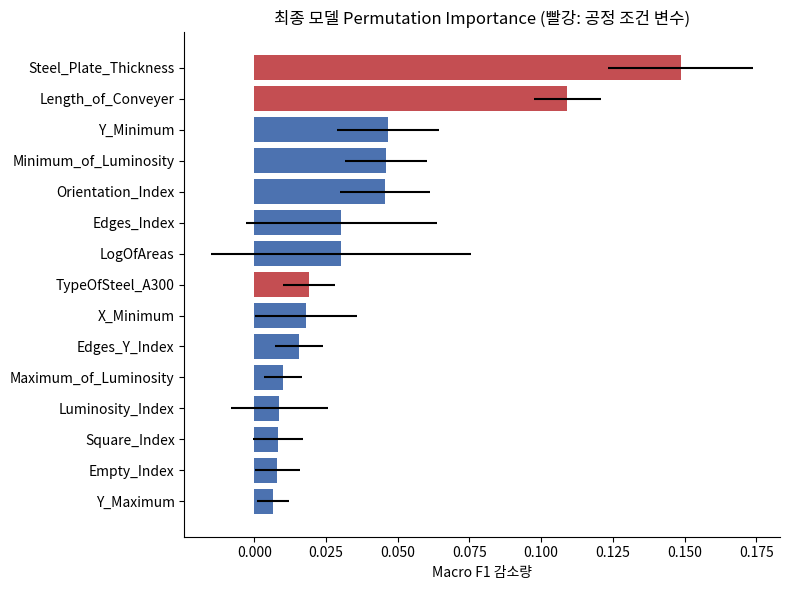

,mean,std
Steel_Plate_Thickness,0.1486,0.0252
Length_of_Conveyer,0.1092,0.0117
Y_Minimum,0.0466,0.0179
Minimum_of_Luminosity,0.0458,0.0143
Orientation_Index,0.0456,0.0156
Edges_Index,0.0304,0.0332
LogOfAreas,0.0303,0.0453
TypeOfSteel_A300,0.0190,0.0092
X_Minimum,0.0181,0.0177
Edges_Y_Index,0.0155,0.0085


In [14]:
from sklearn.inspection import permutation_importance

imp_list = []
for tr_idx, va_idx in CV.split(X_train, y_enc):
    m = make_ensemble(True).fit(X_train.iloc[tr_idx], y_enc[tr_idx])
    r = permutation_importance(m, X_train.iloc[va_idx], y_enc[va_idx], scoring="f1_macro",
                               n_repeats=5, random_state=R)
    imp_list.append(r.importances_mean)

imp = pd.DataFrame(imp_list, columns=X_train.columns)
imp_final = pd.DataFrame({"mean": imp.mean(), "std": imp.std()}).sort_values("mean", ascending=False)

top = imp_final.head(15).iloc[::-1]
process_cols = {"Steel_Plate_Thickness", "Length_of_Conveyer", "TypeOfSteel_A300"}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["mean"], xerr=top["std"],
        color=["#C44E52" if c in process_cols else "#4C72B0" for c in top.index])
ax.set_xlabel("Macro F1 감소량")
ax.set_title("최종 모델 Permutation Importance (빨강: 공정 조건 변수)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

imp_final.head(10).round(4)

**확인 결과**
- 최종 모델도 **`Steel_Plate_Thickness`(0.149)와 `Length_of_Conveyer`(0.109)**에 가장 크게 의존합니다. 공정 조건 지름길 문제는 불균형 처리나 앙상블로 사라지지 않았습니다.
- Baseline XGBoost와 비교하면 `TypeOfSteel_A300`의 중요도가 0.073에서 0.019로 줄고, `Orientation_Index`·`Minimum_of_Luminosity`·`Edges_Index` 등 형상·밝기 Feature가 상대적으로 올라왔습니다.
- `LogOfAreas`는 표준편차(0.045)가 평균(0.030)보다 커서 fold에 따라 중요도가 크게 달라집니다. `Pixels_Areas`와 정보가 거의 같아 둘 중 어느 쪽이 쓰이는지가 fold마다 바뀌기 때문일 수 있습니다.

**해석 시 주의:** 중요도는 "모델이 예측에 활용한 정도"이며, 두께나 컨베이어 길이가 결함의 **원인**이라는 뜻이 아닙니다.

## 8.2 최종 Test 평가

> ⚠️ **실행 전 팀 합의 필요.** 아래 셀은 `RUN_TEST = False`로 막혀 있습니다.
>
> - 최종 모델을 **Train 전체(1,552건)**로 다시 학습한 뒤 Test(389건)에서 **단 한 번** 평가합니다.
> - Test 결과를 본 뒤 모델·처리 방법·하이퍼파라미터를 다시 바꾸면 Test가 사실상 검증용 데이터가 되어 일반화 성능 추정이 무의미해집니다.
> - Stains(14건)·Dirtiness(11건)는 1건당 Recall이 0.071·0.091씩 움직이므로 변동 폭을 감안해 해석합니다.

In [15]:
RUN_TEST = False   # 팀 합의 후 True로 변경하고 이 셀만 실행

if RUN_TEST:
    import joblib

    final_model = make_ensemble(True).fit(X_train, y_enc)
    y_pred_test = decode(final_model.predict(X_test))

    (PROJECT_ROOT / "models").mkdir(exist_ok=True)
    joblib.dump({"model": final_model, "label_encoder": le},
                PROJECT_ROOT / "models" / "final_model.pkl")

    print(classification_report(y_test, y_pred_test, digits=3))
    log_result("FINAL_TEST_Ensemble_BorderlineSMOTE", y_test, y_pred_test,
               note="Test 1회 평가")
    fig, ax, _ = plot_confusion_matrix(y_test, y_pred_test, labels=list(CLASSES),
                                       normalize=True, title="최종 모델 혼동행렬 (Test)",
                                       save_name="confusion_matrix.png")
    plt.show()
else:
    print("RUN_TEST = False → Test 평가를 실행하지 않았습니다.")

RUN_TEST = False → Test 평가를 실행하지 않았습니다.
